# Step 6: Final Findings and Recommendations

**Project:** Can we flag a late order *before* it ships? A leakage-free study of delivery risk at DataCo

This notebook brings the whole project together on one page: the key charts, the model results and the business recommendations.
It also saves the charts as images (`figures/` folder) for the presentation slides.

| Step | Notebook | Technique |
|---|---|---|
| 1 | `01_data_audit` | Data understanding, cleaning, leakage check |
| 2 | `02_eda_delivery_and_profit` | Exploratory analysis, chi-square tests, Cramér's V |
| 3 | `03_classification_late_risk` | Logistic Regression, Random Forest, XGBoost (classification) |
| 4 | `04_regression_shipping_days` | Linear, Ridge, Random Forest, XGBoost (regression) |
| 5 | `05_clustering_customers` | K-Means, Hierarchical (Ward), PCA (clustering) |
| 6 | this notebook | Summary and recommendations |

## Setup

In [1]:
import sys, os, subprocess
IN_COLAB = "google.colab" in sys.modules
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid", font_scale=1.05)
BLUE, ORANGE, GREY, RED = "#4C72B0", "#DD8452", "#9A9A9A", "#C44E52"
pct = plt.FuncFormatter(lambda y, _: f"{y:.0%}")

FIG_DIR = "/content/figures" if IN_COLAB else os.path.join("..", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight", facecolor="white")

In [2]:
def find_processed_dir():
    candidates = ["/content/drive/MyDrive/dataco-final-project/processed",
                  "/content/dataco-final-project/processed",
                  os.path.join("..", "data", "processed")]
    if IN_COLAB:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
    for c in candidates:
        if os.path.exists(os.path.join(c, "orders_clean.parquet")):
            return c
    return None

def rebuild_orders_from_raw():
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    data_dir = kagglehub.dataset_download("shashwatwork/dataco-smart-supply-chain-for-big-data-analysis")
    raw = pd.read_csv(os.path.join(data_dir, "DataCoSupplyChainDataset.csv"), encoding="latin-1")
    raw["order_date"] = pd.to_datetime(raw["order date (DateOrders)"])
    orders = (raw.groupby("Order Id")
                 .agg(order_date=("order_date", "first"), customer_id=("Customer Id", "first"),
                      customer_segment=("Customer Segment", "first"), market=("Market", "first"),
                      order_region=("Order Region", "first"), order_country=("Order Country", "first"),
                      shipping_mode=("Shipping Mode", "first"), payment_type=("Type", "first"),
                      days_scheduled=("Days for shipment (scheduled)", "first"),
                      days_real=("Days for shipping (real)", "first"),
                      late=("Late_delivery_risk", "first"),
                      delivery_status=("Delivery Status", "first"),
                      n_items=("Order Item Id", "count"), total_quantity=("Order Item Quantity", "sum"),
                      gross_sales=("Sales", "sum"), net_sales=("Order Item Total", "sum"),
                      total_discount=("Order Item Discount", "sum"), profit=("Benefit per order", "sum"),
                      n_categories=("Category Name", "nunique"))
                 .reset_index().rename(columns={"Order Id": "order_id"}))
    orders["is_canceled"] = orders["delivery_status"].eq("Shipping canceled")
    orders["avg_discount_rate"] = orders["total_discount"] / orders["gross_sales"]
    orders["profit_margin"] = orders["profit"] / orders["net_sales"]
    orders["delay_gap"] = orders["days_real"] - orders["days_scheduled"]
    return orders


proc = find_processed_dir()
orders = (pd.read_parquet(os.path.join(proc, "orders_clean.parquet")) if proc else rebuild_orders_from_raw())
shipped = orders[~orders["is_canceled"]].copy()
shipped["order_hour"] = shipped["order_date"].dt.hour
print(f"Shipped orders: {len(shipped):,}")

Shipped orders: 62,897


## Finding 1: Late delivery is a broken promise, not a broken delivery

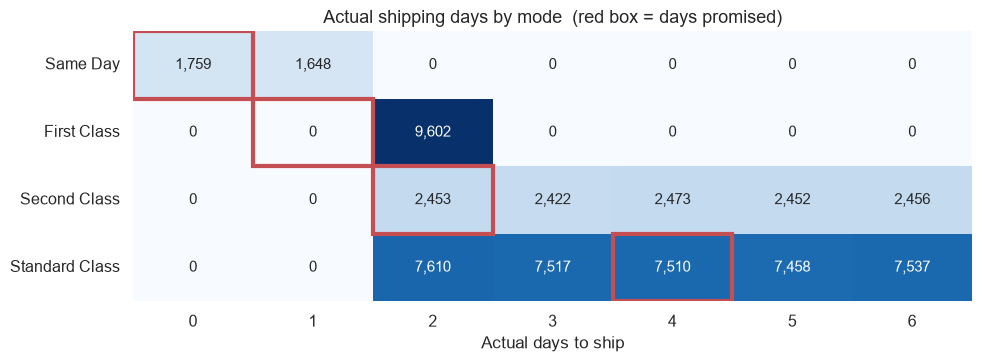

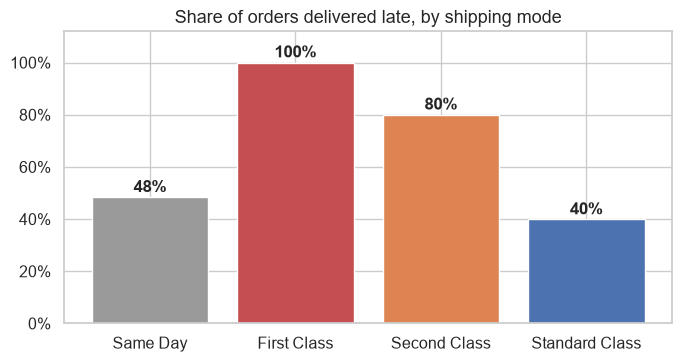

In [3]:
mode_order = ["Same Day", "First Class", "Second Class", "Standard Class"]
promised = shipped.groupby("shipping_mode")["days_scheduled"].first().reindex(mode_order)
table = pd.crosstab(shipped["shipping_mode"], shipped["days_real"]).reindex(mode_order)

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.heatmap(table, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax, annot_kws={"size": 11})
for i, mode in enumerate(mode_order):
    ax.add_patch(plt.Rectangle((promised[mode], i), 1, 1, fill=False, edgecolor=RED, lw=3))
ax.set_title("Actual shipping days by mode  (red box = days promised)", fontsize=13)
ax.set_xlabel("Actual days to ship"); ax.set_ylabel("")
plt.tight_layout(); save(fig, "fig1_promise_vs_actual.png"); plt.show()

late_by_mode = shipped.groupby("shipping_mode")["late"].mean().reindex(mode_order)
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(late_by_mode.index, late_by_mode.values, color=[GREY, RED, ORANGE, BLUE])
for b, v in zip(bars, late_by_mode.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.0%}", ha="center", fontsize=12, fontweight="bold")
ax.set_ylim(0, 1.12); ax.yaxis.set_major_formatter(pct)
ax.set_title("Share of orders delivered late, by shipping mode", fontsize=13)
plt.tight_layout(); save(fig, "fig2_late_by_mode.png"); plt.show()

- **First Class** always takes 2 days but promises 1, so **100% late**.
- **Second and Standard Class** take the *same* 2–6 days. Second Class just promises less (2 vs 4 days), so it's 80% late vs 40%.

## Finding 2: A hidden noon cut-off for Same Day shipping

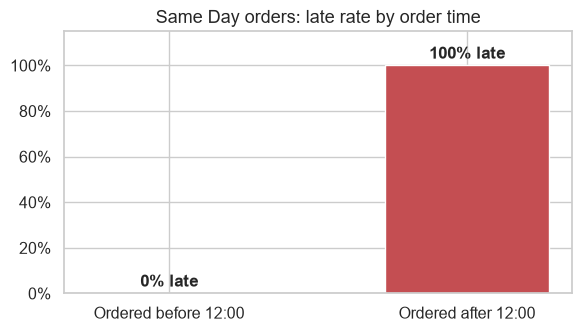

In [4]:
same_day = shipped[shipped["shipping_mode"] == "Same Day"]
noon = same_day.groupby(np.where(same_day["order_hour"] < 12, "Ordered before 12:00", "Ordered after 12:00"))["late"].mean()
noon = noon.reindex(["Ordered before 12:00", "Ordered after 12:00"])
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(noon.index, noon.values, color=[BLUE, RED], width=0.55)
for b, v in zip(bars, noon.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.03, f"{v:.0%} late", ha="center", fontsize=12, fontweight="bold")
ax.set_ylim(0, 1.15); ax.yaxis.set_major_formatter(pct)
ax.set_title("Same Day orders: late rate by order time", fontsize=13)
plt.tight_layout(); save(fig, "fig3_same_day_noon.png"); plt.show()

## Finding 3: Region, customer and product don't matter

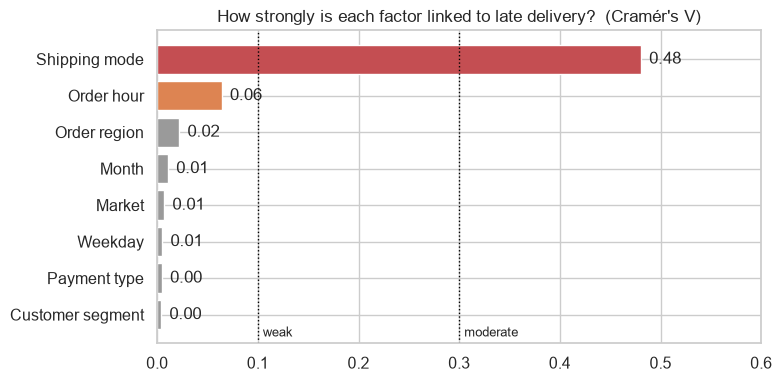

In [5]:
def cramers_v(df, col, target="late"):
    t = pd.crosstab(df[col], df[target])
    chi2 = chi2_contingency(t)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))

shipped["order_weekday"] = shipped["order_date"].dt.day_name()
shipped["order_month"] = shipped["order_date"].dt.month
labels = {"shipping_mode": "Shipping mode", "order_hour": "Order hour", "order_region": "Order region",
          "market": "Market", "order_month": "Month", "customer_segment": "Customer segment",
          "order_weekday": "Weekday", "payment_type": "Payment type"}
effects = pd.Series({labels[c]: cramers_v(shipped, c) for c in labels}).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(effects.index, effects.values, color=[RED if v > 0.3 else ORANGE if v > 0.05 else GREY for v in effects.values])
for i, v in enumerate(effects.values):
    ax.text(v + 0.008, i, f"{v:.2f}", va="center")
ax.axvline(0.1, color="black", ls=":", lw=1); ax.text(0.105, -0.6, "weak", fontsize=9)
ax.axvline(0.3, color="black", ls=":", lw=1); ax.text(0.305, -0.6, "moderate", fontsize=9)
ax.set_xlim(0, 0.6)
ax.set_title("How strongly is each factor linked to late delivery?  (Cramér's V)", fontsize=12)
plt.tight_layout(); save(fig, "fig4_what_drives_delay.png"); plt.show()

## Finding 4: Honest models hit the ceiling; the 99% models were cheating
Results from Step 3 (classification) and Step 4 (regression), test set = Jul 2017 – Jan 2018.

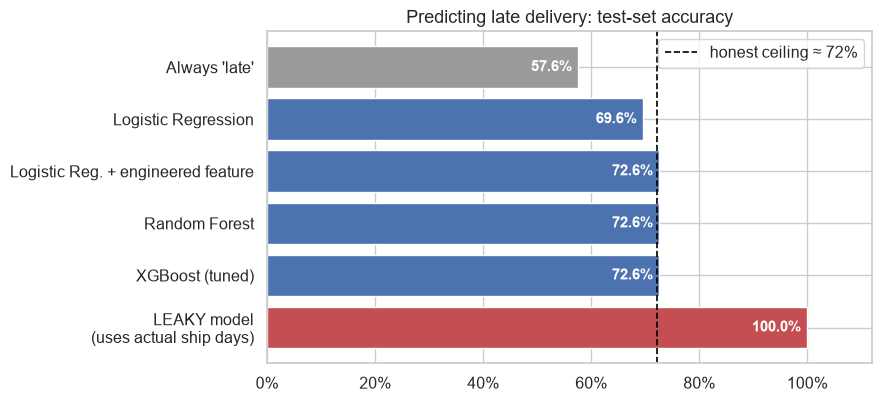

,model,accuracy,recall_late,roc_auc
0,Always 'late',0.576,1.000,NaN
1,Logistic Regression,0.696,0.539,0.753
2,Logistic Reg. + engineered feature,0.726,0.592,0.781
3,Random Forest,0.726,0.592,0.780
4,XGBoost (tuned),0.726,0.592,0.779
5,LEAKY model\n(uses actual ship days),1.000,1.000,1.000


In [6]:
clf = pd.DataFrame({
    "model": ["Always 'late'", "Logistic Regression", "Logistic Reg. + engineered feature",
              "Random Forest", "XGBoost (tuned)", "LEAKY model\n(uses actual ship days)"],
    "accuracy": [0.576, 0.696, 0.726, 0.726, 0.726, 1.000],
    "recall_late": [1.000, 0.539, 0.592, 0.592, 0.592, 1.000],
    "roc_auc": [np.nan, 0.753, 0.781, 0.780, 0.779, 1.000],
})
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = [GREY, BLUE, BLUE, BLUE, BLUE, RED]
bars = ax.barh(clf["model"], clf["accuracy"], color=colors)
for b, v in zip(bars, clf["accuracy"]):
    ax.text(v - 0.012, b.get_y() + b.get_height() / 2, f"{v:.1%}", va="center", ha="right",
            fontsize=11, color="white", fontweight="bold")
ax.axvline(0.722, color="black", ls="--", lw=1.2, label="honest ceiling ≈ 72%")
ax.legend(loc="upper right")
ax.set_xlim(0, 1.12); ax.xaxis.set_major_formatter(pct); ax.invert_yaxis()
ax.set_title("Predicting late delivery: test-set accuracy", fontsize=13)
plt.tight_layout(); save(fig, "fig5_classification_results.png"); plt.show()
clf

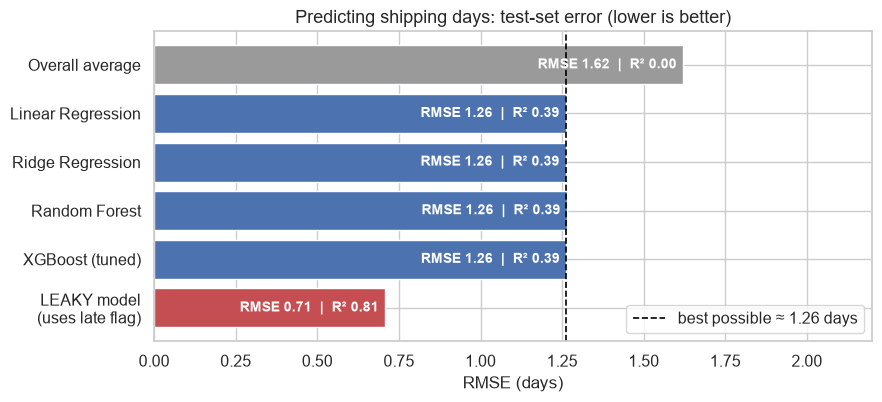

,model,RMSE_days,R2
0,Overall average,1.621,0.000
1,Linear Regression,1.262,0.394
2,Ridge Regression,1.262,0.394
3,Random Forest,1.265,0.391
4,XGBoost (tuned),1.263,0.393
5,LEAKY model\n(uses late flag),0.708,0.809


In [7]:
reg = pd.DataFrame({
    "model": ["Overall average", "Linear Regression", "Ridge Regression", "Random Forest", "XGBoost (tuned)",
              "LEAKY model\n(uses late flag)"],
    "RMSE_days": [1.621, 1.262, 1.262, 1.265, 1.263, 0.708],
    "R2": [0.000, 0.394, 0.394, 0.391, 0.393, 0.809],
})
fig, ax = plt.subplots(figsize=(9, 4.2))
bars = ax.barh(reg["model"], reg["RMSE_days"], color=[GREY, BLUE, BLUE, BLUE, BLUE, RED])
for b, v, r in zip(bars, reg["RMSE_days"], reg["R2"]):
    ax.text(v - 0.02, b.get_y() + b.get_height() / 2, f"RMSE {v:.2f}  |  R² {r:.2f}", va="center", ha="right",
            fontsize=10, color="white", fontweight="bold")
ax.axvline(1.262, color="black", ls="--", lw=1.2, label="best possible ≈ 1.26 days")
ax.legend(loc="lower right")
ax.set_xlim(0, 2.2); ax.set_xlabel("RMSE (days)"); ax.invert_yaxis()
ax.set_title("Predicting shipping days: test-set error (lower is better)", fontsize=13)
plt.tight_layout(); save(fig, "fig6_regression_results.png"); plt.show()
reg

## Finding 5: Four customer groups with very different value

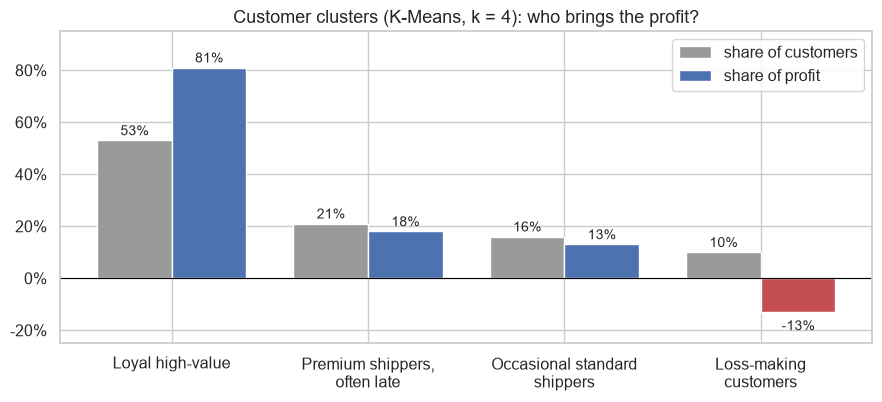

,cluster,share_of_customers,share_of_profit,late_share
0,Loyal high-value,0.53,0.81,0.58
1,"Premium shippers,\noften late",0.21,0.18,0.78
2,Occasional standard\nshippers,0.16,0.13,0.24
3,Loss-making\ncustomers,0.10,-0.13,0.62


In [8]:
clusters = pd.DataFrame({
    "cluster": ["Loyal high-value", "Premium shippers,\noften late", "Occasional standard\nshippers", "Loss-making\ncustomers"],
    "share_of_customers": [0.53, 0.21, 0.16, 0.10],
    "share_of_profit": [0.81, 0.18, 0.13, -0.13],
    "late_share": [0.58, 0.78, 0.24, 0.62],
})
x = np.arange(len(clusters)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4.2))
b1 = ax.bar(x - w / 2, clusters["share_of_customers"], w, label="share of customers", color=GREY)
b2 = ax.bar(x + w / 2, clusters["share_of_profit"], w, label="share of profit",
            color=[BLUE if v >= 0 else RED for v in clusters["share_of_profit"]])
for bars in (b1, b2):
    for b in bars:
        v = b.get_height()
        ax.text(b.get_x() + b.get_width() / 2, v + (0.02 if v >= 0 else -0.07), f"{v:.0%}", ha="center", fontsize=10)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(clusters["cluster"])
ax.yaxis.set_major_formatter(pct); ax.set_ylim(-0.25, 0.95); ax.legend()
ax.set_title("Customer clusters (K-Means, k = 4): who brings the profit?", fontsize=13)
plt.tight_layout(); save(fig, "fig7_customer_clusters.png"); plt.show()
clusters

## Business recommendations

| # | Recommendation | Evidence |
|---|---|---|
| 1 | **Change the First Class promise to 2 days** (or truly ship it in 1). This alone removes about 27% of all late orders | First Class: 100% late, always 2 days vs 1 promised |
| 2 | **Fix or re-price Second Class.** It ships no faster than Standard | Both take 2–6 days evenly; Second is 80% late vs 40% |
| 3 | **Show the 12:00 cut-off for Same Day shipping** at checkout | Before noon: 0% late; after noon: 100% late |
| 4 | **Quote a delivery range ("2–6 days")** for Second/Standard instead of one date | Even the best model is about 1.2 days off for these modes |
| 5 | **Win back the "Premium, often late" customers** (21%) | They pay for speed, get 78% late deliveries, and have gone inactive |
| 6 | **Review pricing for loss-making customers** (10%) | Average margin −29%, wiping out about 13% of the profit |
| 7 | **Don't spend on region- or product-specific delivery fixes** | Region, product and customer type show no effect on lateness |

## Limitations
- The dataset is **partly simulated**: shipping days are evenly random within 2–6 days, about 19% of orders lose money in every group, and 96% of customers return regardless of late delivery.
- **Customer IDs reset from October 2017**, so customer-level analysis uses earlier data only.
- **No carrier, warehouse or distance data**, which in real life would explain more of the delay.
- The costs used for the decision threshold (5 for a missed late order, 1 for a false alarm) are **assumptions**.

## What I would do next with real company data
- Add carrier, warehouse and distance information to explain the random 2–6 day spread.
- Measure the real cost of a late order (complaints, refunds, churn) to set the threshold properly.
- Run an A/B test of the new First Class promise and track customer satisfaction.

In [9]:
print('Figures saved to', os.path.abspath(FIG_DIR)); print(sorted(os.listdir(FIG_DIR)))

Figures saved to C:\Users\emraa\Downloads\claude work\dataco-final-project\figures
['fig1_promise_vs_actual.png', 'fig2_late_by_mode.png', 'fig3_same_day_noon.png', 'fig4_what_drives_delay.png', 'fig5_classification_results.png', 'fig6_regression_results.png', 'fig7_customer_clusters.png']
